# Lab 3: Regression & Classification
### Age & Gender Prediction from the Abalone Dataset

**Dataset:** [Abalone Dataset (Kaggle)](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset) — physical
measurements of abalone (sea snails) used to predict **age** and **sex**.

> Note: The original dataset is used to predict "age" (from the number of shell rings) and "sex" (M/F/I),
> standing in for the Age/Gender Prediction from face images task in the original assignment. The Machine
> Learning pipeline (Regression / Classification / PCA / Evaluation) is identical in principle.

**Table of contents**
1. LAB 1: Regression (Simple, Multiple, Age Prediction)
2. LAB 2: Classification (Data Prep, Decision Boundary, Logistic Regression, Gender Prediction, Confusion Matrix)
3. LAB 3: Model Comparison


## 0. Setup & Import Libraries

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, RocCurveDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 0.1 Load Dataset

The Abalone dataset has 4,177 samples, 8 features, and 1 target (Rings).

| Column | Description |
|---|---|
| Sex | M (Male), F (Female), I (Infant) |
| Length | Shell length (mm) |
| Diameter | Shell diameter (mm) |
| Height | Shell height (mm) |
| Whole weight | Whole animal weight (g) |
| Shucked weight | Meat weight (g) |
| Viscera weight | Gut weight (g) |
| Shell weight | Shell weight (g) |
| Rings | Number of shell rings -> **Age = Rings + 1.5 (years)** |


In [8]:
columns = ["Sex", "Length", "Diameter", "Height", "Whole_weight",
           "Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"]
df = pd.read_csv("../data/abalone.csv", names=columns)

# Create the Age column using the standard Abalone dataset formula
df["Age"] = df["Rings"] + 1.5

print("Shape:", df.shape)
df.head()


Shape: (4177, 10)


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Age
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,16.5
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,8.5
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,10.5
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,11.5
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,8.5


In [9]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sex,4177,3,M,1528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Length,4177.0,NaN,NaN,NaN,0.523992,0.120093,0.075,0.45,0.545,0.615,0.815
Diameter,4177.0,NaN,NaN,NaN,0.407881,0.09924,0.055,0.35,0.425,0.48,0.65
Height,4177.0,NaN,NaN,NaN,0.139516,0.041827,0.0,0.115,0.14,0.165,1.13
Whole_weight,4177.0,NaN,NaN,NaN,0.828742,0.490389,0.002,0.4415,0.7995,1.153,2.8255
Shucked_weight,4177.0,NaN,NaN,NaN,0.359367,0.221963,0.001,0.186,0.336,0.502,1.488
Viscera_weight,4177.0,NaN,NaN,NaN,0.180594,0.109614,0.0005,0.0935,0.171,0.253,0.76
Shell_weight,4177.0,NaN,NaN,NaN,0.238831,0.139203,0.0015,0.13,0.234,0.329,1.005
Rings,4177.0,NaN,NaN,NaN,9.933684,3.224169,1.0,8.0,9.0,11.0,29.0
Age,4177.0,NaN,NaN,NaN,11.433684,3.224169,2.5,9.5,10.5,12.5,30.5


In [10]:
# Check for missing values and the distribution of Sex
print(df.isna().sum())
print()
print(df["Sex"].value_counts())


Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
Age               0
dtype: int64

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


C:\Users\Watcharakorn\AppData\Local\Temp\ipykernel_11460\1864212904.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Sex", data=df, ax=axes[1], palette="Set2")


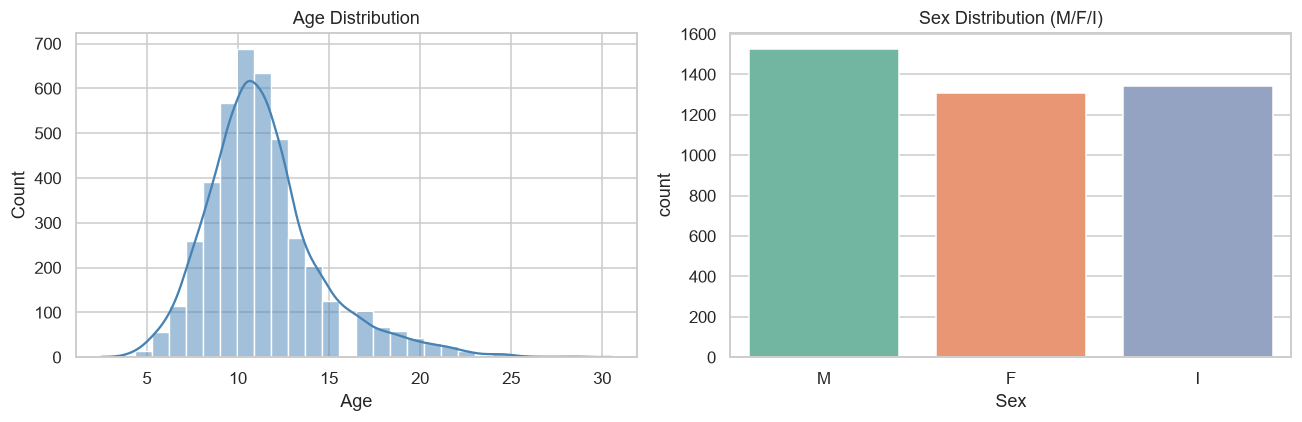

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Age"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Age Distribution")
sns.countplot(x="Sex", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Sex Distribution (M/F/I)")
plt.tight_layout()
plt.savefig("../images/00_eda_distribution.png", bbox_inches="tight")
plt.show()


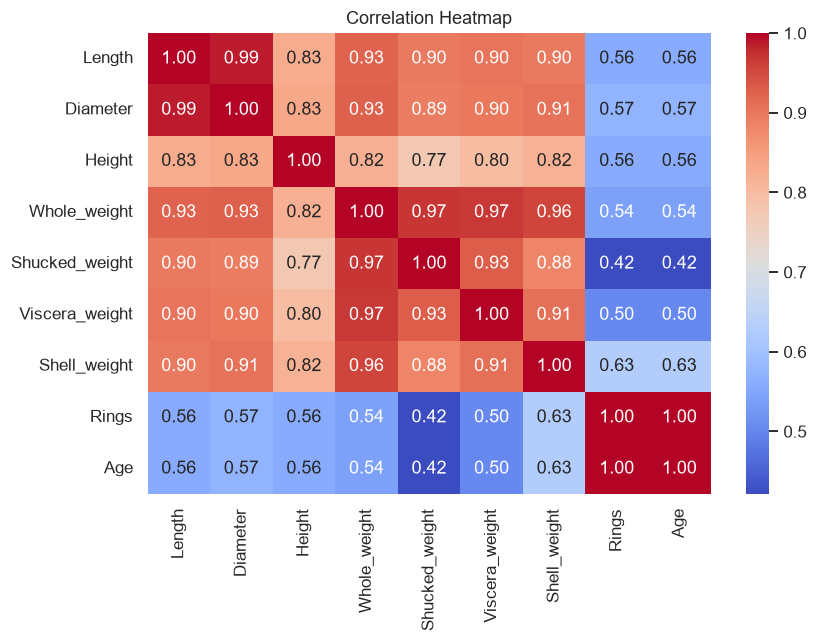

In [12]:
plt.figure(figsize=(8, 6))
numeric_cols = ["Length","Diameter","Height","Whole_weight",
                 "Shucked_weight","Viscera_weight","Shell_weight","Rings","Age"]
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/01_correlation_heatmap.png", bbox_inches="tight")
plt.show()


**Observation:** `Shell_weight` has the highest correlation with `Rings`/`Age` among single features,
making it a natural choice for Simple Linear Regression.


---
# LAB 1: Regression

## 1.1 Simple Linear Regression
Predict **Age** from a single feature: `Shell_weight`


In [13]:
X_simple = df[["Shell_weight"]]
y = df["Age"]

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=RANDOM_STATE
)

simple_lr = LinearRegression()
simple_lr.fit(X_train_s, y_train)

y_pred_train_s = simple_lr.predict(X_train_s)
y_pred_test_s = simple_lr.predict(X_test_s)

print(f"Coefficient: {simple_lr.coef_[0]:.4f}, Intercept: {simple_lr.intercept_:.4f}")
print(f"Train R2: {r2_score(y_train, y_pred_train_s):.4f}  |  Test R2: {r2_score(y_test, y_pred_test_s):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_test_s):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test_s)):.4f}")


Coefficient: 14.3477, Intercept: 8.0058
Train R2: 0.3919  |  Test R2: 0.4009
Test MAE: 1.8561
Test RMSE: 2.5467


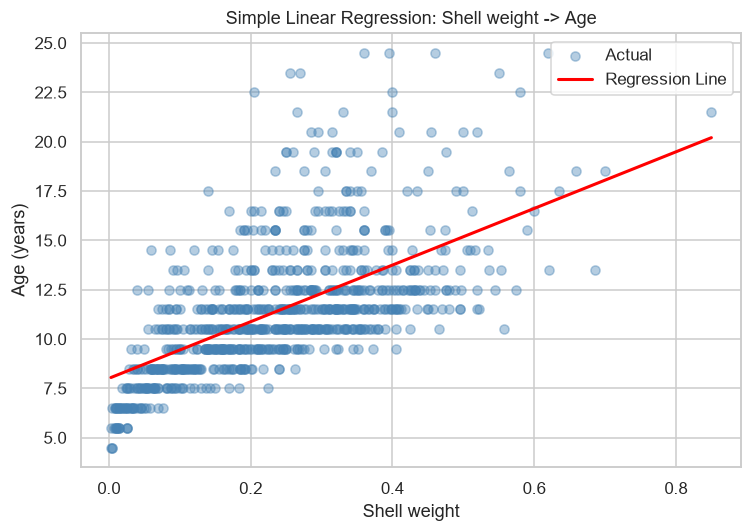

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test_s, y_test, alpha=0.4, label="Actual", color="steelblue")
order = np.argsort(X_test_s["Shell_weight"].values)
plt.plot(X_test_s["Shell_weight"].values[order], y_pred_test_s[order],
         color="red", linewidth=2, label="Regression Line")
plt.xlabel("Shell weight")
plt.ylabel("Age (years)")
plt.title("Simple Linear Regression: Shell weight -> Age")
plt.legend()
plt.tight_layout()
plt.savefig("../images/02_simple_linear_regression.png", bbox_inches="tight")
plt.show()


## 1.2 Multiple Linear Regression
Predict **Age** from all numeric features (excluding Rings, since it is used to compute Age directly),
plus `Sex` one-hot encoded.


In [15]:
df_enc = pd.get_dummies(df, columns=["Sex"], drop_first=True)  # Sex_I, Sex_M

feature_cols = ["Length","Diameter","Height","Whole_weight","Shucked_weight",
                 "Viscera_weight","Shell_weight","Sex_I","Sex_M"]
X_multi = df_enc[feature_cols]
y = df_enc["Age"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=RANDOM_STATE
)

multi_lr = LinearRegression()
multi_lr.fit(X_train_m, y_train_m)

y_pred_train_m = multi_lr.predict(X_train_m)
y_pred_test_m = multi_lr.predict(X_test_m)

print(f"Train R2: {r2_score(y_train_m, y_pred_train_m):.4f}  |  Test R2: {r2_score(y_test_m, y_pred_test_m):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test_m, y_pred_test_m):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test_m, y_pred_test_m)):.4f}")

coef_df = pd.DataFrame({"Feature": feature_cols, "Coefficient": multi_lr.coef_}).sort_values(
    "Coefficient", key=abs, ascending=False
)
coef_df


Train R2: 0.5348  |  Test R2: 0.5482
Test MAE: 1.5931
Test RMSE: 2.2116


,Feature,Coefficient
4,Shucked_weight,-20.256545
1,Diameter,11.123391
2,Height,10.445325
5,Viscera_weight,-9.558916
3,Whole_weight,8.932176
6,Shell_weight,8.792378
7,Sex_I,-0.718974
0,Length,-0.201554
8,Sex_M,0.103276


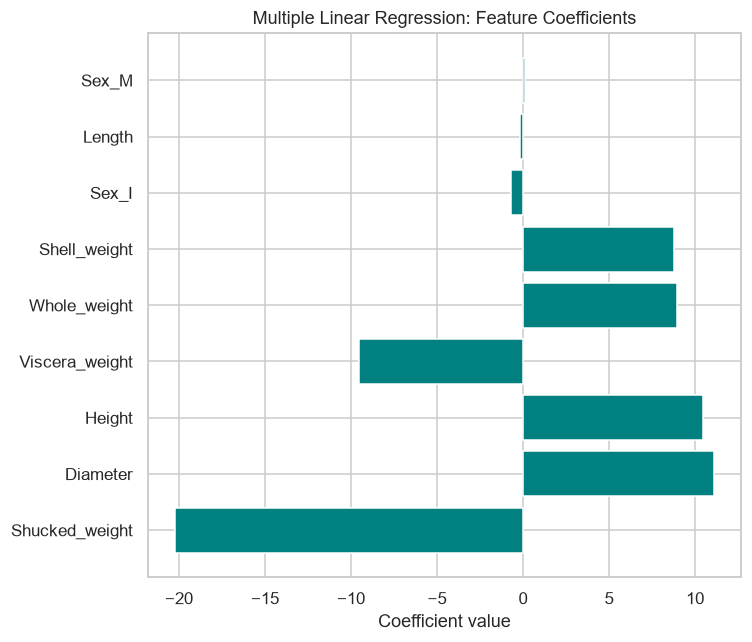

In [16]:
plt.figure(figsize=(7, 6))
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color="teal")
plt.xlabel("Coefficient value")
plt.title("Multiple Linear Regression: Feature Coefficients")
plt.tight_layout()
plt.savefig("../images/03_multiple_regression_coefficients.png", bbox_inches="tight")
plt.show()


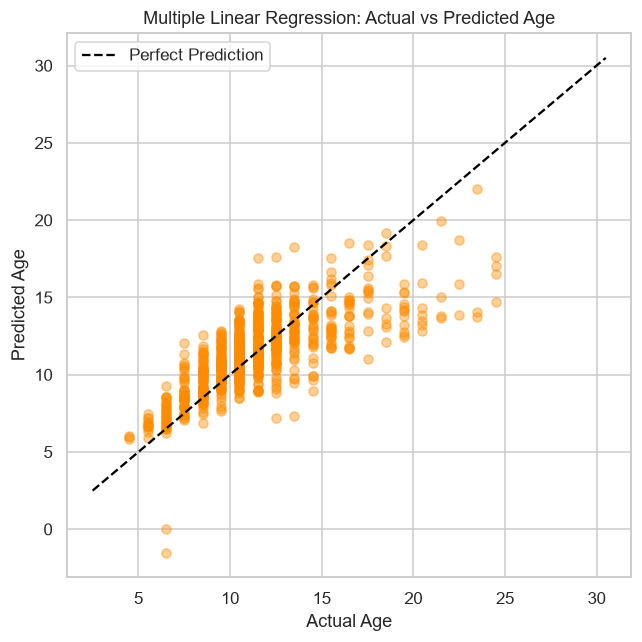

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_m, y_pred_test_m, alpha=0.4, color="darkorange")
lims = [y.min(), y.max()]
plt.plot(lims, lims, color="black", linestyle="--", label="Perfect Prediction")
plt.xlabel("Actual Age")
plt.ylabel("Predicted Age")
plt.title("Multiple Linear Regression: Actual vs Predicted Age")
plt.legend()
plt.tight_layout()
plt.savefig("../images/04_multiple_regression_actual_vs_pred.png", bbox_inches="tight")
plt.show()


## 1.3 PCA + Regression (Dimensionality Reduction)
Apply Principal Component Analysis (PCA) to reduce the 7 continuous physical features down to the
components that explain the most variance, then build a Regression model on top to see how performance changes.


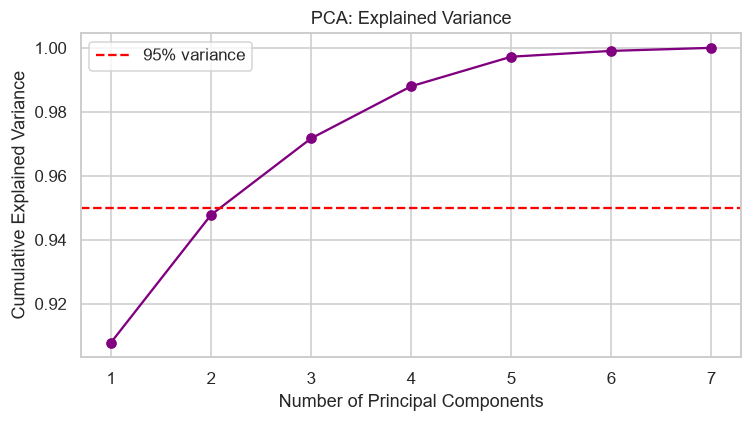

Number of components explaining >= 95% variance: 3


In [18]:
numeric_feats = ["Length","Diameter","Height","Whole_weight",
                  "Shucked_weight","Viscera_weight","Shell_weight"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[numeric_feats])

pca_full = PCA().fit(X_scaled)
explained = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(explained)+1), explained, marker="o", color="purple")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Explained Variance")
plt.legend()
plt.tight_layout()
plt.savefig("../images/05_pca_explained_variance.png", bbox_inches="tight")
plt.show()

n_components = np.argmax(explained >= 0.95) + 1
print(f"Number of components explaining >= 95% variance: {n_components}")


In [19]:
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_pca, df["Age"], test_size=0.2, random_state=RANDOM_STATE
)

pca_lr = LinearRegression()
pca_lr.fit(X_train_p, y_train_p)
y_pred_test_p = pca_lr.predict(X_test_p)

print(f"PCA + Linear Regression -> Test R2: {r2_score(y_test_p, y_pred_test_p):.4f}, "
      f"RMSE: {np.sqrt(mean_squared_error(y_test_p, y_pred_test_p)):.4f}")


PCA + Linear Regression -> Test R2: 0.3928, RMSE: 2.5638


## 1.4 Age Prediction Summary (LAB 1)
Simple vs Multiple vs PCA-based Linear Regression are compared side by side in LAB 3 below.


---
# LAB 2: Classification

## 2.1 Preparing Classification Data
Predict the **gender** of the abalone: use only Male (M) and Female (F) samples (Infants are excluded,
since they are not yet mature and cannot be biologically sexed) -> this makes the problem a
**Binary Classification** task.


In [20]:
df_clf = df[df["Sex"].isin(["M", "F"])].copy()
le = LabelEncoder()
df_clf["Gender"] = le.fit_transform(df_clf["Sex"])  # F=0, M=1
print(dict(zip(le.classes_, le.transform(le.classes_))))
print(df_clf["Gender"].value_counts())

feature_cols_clf = ["Length","Diameter","Height","Whole_weight",
                     "Shucked_weight","Viscera_weight","Shell_weight"]
X_clf = df_clf[feature_cols_clf]
y_clf = df_clf["Gender"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

scaler_clf = StandardScaler()
X_train_c_scaled = scaler_clf.fit_transform(X_train_c)
X_test_c_scaled = scaler_clf.transform(X_test_c)
print("Train shape:", X_train_c_scaled.shape, " Test shape:", X_test_c_scaled.shape)


{'F': np.int64(0), 'M': np.int64(1)}
Gender
1    1528
0    1307
Name: count, dtype: int64
Train shape: (2268, 7)  Test shape: (567, 7)


## 2.2 Decision Boundary Visualization
Use the two features most related to gender (`Shell_weight`, `Diameter`) to visualize the decision
boundary in 2D.


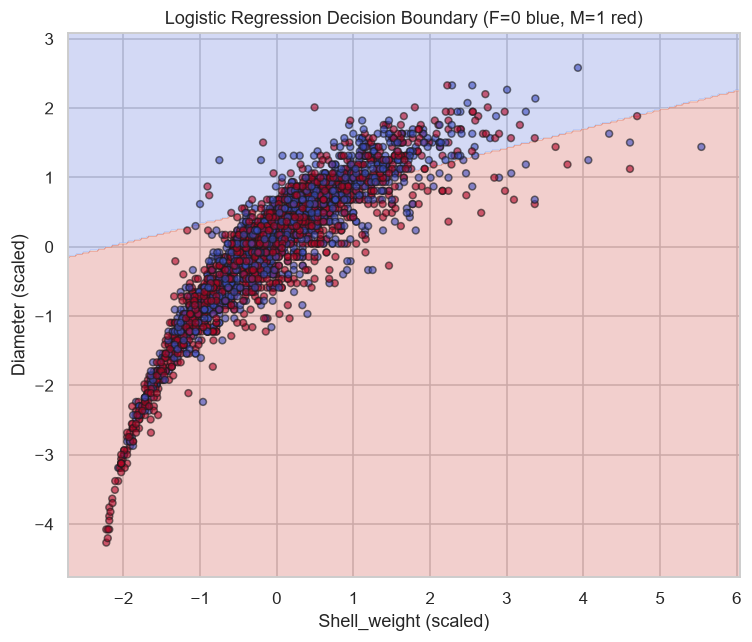

In [21]:
feat_x, feat_y = "Shell_weight", "Diameter"
X_2d = df_clf[[feat_x, feat_y]].values
y_2d = df_clf["Gender"].values

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

clf_2d = LogisticRegression(random_state=RANDOM_STATE)
clf_2d.fit(X_2d_scaled, y_2d)

xx, yy = np.meshgrid(
    np.linspace(X_2d_scaled[:,0].min()-0.5, X_2d_scaled[:,0].max()+0.5, 300),
    np.linspace(X_2d_scaled[:,1].min()-0.5, X_2d_scaled[:,1].max()+0.5, 300)
)
Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
scatter = plt.scatter(X_2d_scaled[:,0], X_2d_scaled[:,1], c=y_2d, cmap="coolwarm",
                       edgecolor="k", alpha=0.6, s=20)
plt.xlabel(f"{feat_x} (scaled)")
plt.ylabel(f"{feat_y} (scaled)")
plt.title("Logistic Regression Decision Boundary (F=0 blue, M=1 red)")
plt.tight_layout()
plt.savefig("../images/06_decision_boundary.png", bbox_inches="tight")
plt.show()


## 2.3 Logistic Regression (Full Feature Set) & Gender Prediction


In [22]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_c_scaled, y_train_c)

y_pred_c = log_reg.predict(X_test_c_scaled)
y_proba_c = log_reg.predict_proba(X_test_c_scaled)[:, 1]

acc = accuracy_score(y_test_c, y_pred_c)
prec = precision_score(y_test_c, y_pred_c)
rec = recall_score(y_test_c, y_pred_c)
f1 = f1_score(y_test_c, y_pred_c)
auc = roc_auc_score(y_test_c, y_proba_c)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")


Accuracy : 0.5309
Precision: 0.5518
Recall   : 0.6961
F1-score : 0.6156
AUC      : 0.5668


## 2.4 Confusion Matrix

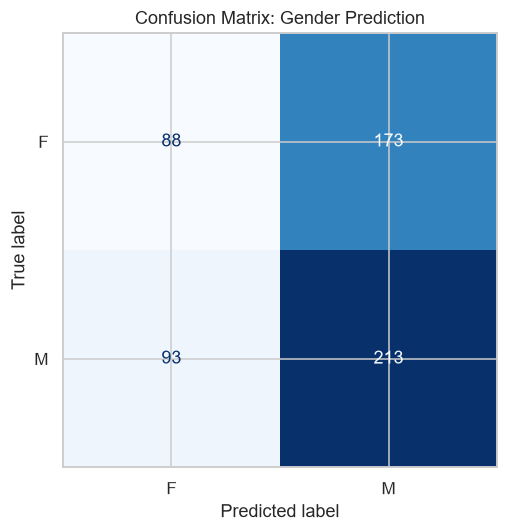

In [23]:
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(5.5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix: Gender Prediction")
plt.tight_layout()
plt.savefig("../images/07_confusion_matrix.png", bbox_inches="tight")
plt.show()


## 2.5 ROC Curve & AUC

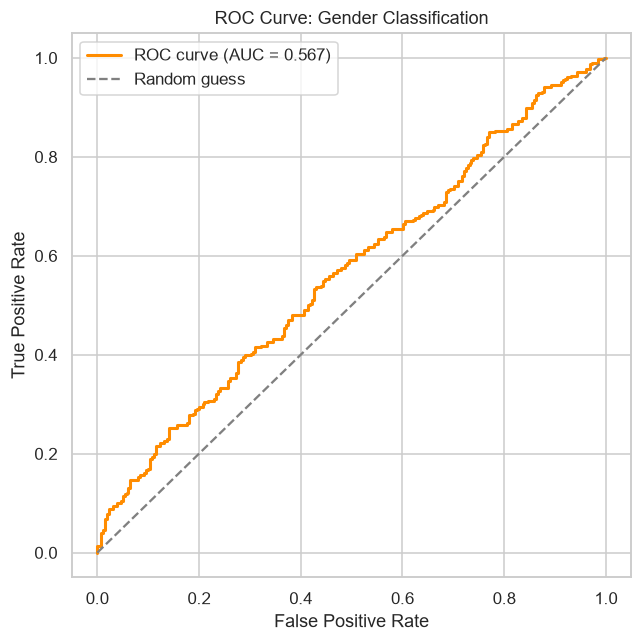

In [24]:
fpr, tpr, thresholds = roc_curve(y_test_c, y_proba_c)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="darkorange", linewidth=2, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Gender Classification")
plt.legend()
plt.tight_layout()
plt.savefig("../images/08_roc_curve.png", bbox_inches="tight")
plt.show()


---
# LAB 3: Model Comparison

## 3.1 Simple vs Multiple Linear Regression


In [25]:
reg_compare = pd.DataFrame({
    "Model": ["Simple LR (Shell_weight)", "Multiple LR (all features)", "PCA + LR"],
    "Train R2": [
        r2_score(y_train, y_pred_train_s),
        r2_score(y_train_m, y_pred_train_m),
        r2_score(y_train_p, pca_lr.predict(X_train_p)),
    ],
    "Test R2": [
        r2_score(y_test, y_pred_test_s),
        r2_score(y_test_m, y_pred_test_m),
        r2_score(y_test_p, y_pred_test_p),
    ],
    "Test MAE": [
        mean_absolute_error(y_test, y_pred_test_s),
        mean_absolute_error(y_test_m, y_pred_test_m),
        mean_absolute_error(y_test_p, y_pred_test_p),
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_test_s)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_test_m)),
        np.sqrt(mean_squared_error(y_test_p, y_pred_test_p)),
    ],
})
reg_compare


,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Simple LR (Shell_weight),0.391886,0.400853,1.856075,2.546741
1,Multiple LR (all features),0.534824,0.548163,1.593107,2.211613
2,PCA + LR,0.359121,0.392819,1.839579,2.563760


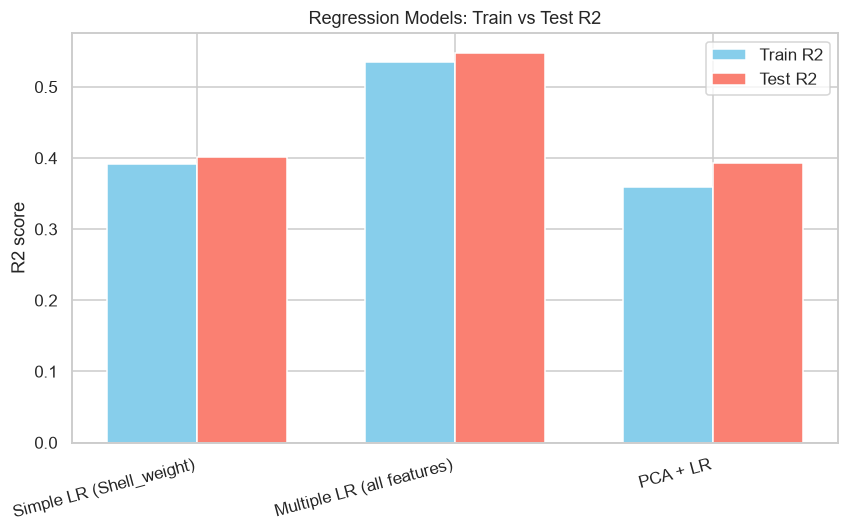

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(reg_compare))
width = 0.35
ax.bar(x - width/2, reg_compare["Train R2"], width, label="Train R2", color="skyblue")
ax.bar(x + width/2, reg_compare["Test R2"], width, label="Test R2", color="salmon")
ax.set_xticks(x)
ax.set_xticklabels(reg_compare["Model"], rotation=15, ha="right")
ax.set_ylabel("R2 score")
ax.set_title("Regression Models: Train vs Test R2")
ax.legend()
plt.tight_layout()
plt.savefig("../images/09_regression_comparison.png", bbox_inches="tight")
plt.show()


**Summary:**
- **Simple Linear Regression** uses a single feature, is simple to interpret, but has limited performance (lower R2)
- **Multiple Linear Regression** uses several features, capturing relationships better (higher R2), but is
  harder to interpret and risks multicollinearity
- **PCA + Linear Regression** reduces the dimensionality of the data before modeling, which helps with
  multicollinearity and overfitting on datasets with many features. In this case (relatively few features with
  a clear linear relationship already), results are close to Multiple LR.

## 3.2 Training vs Testing Performance (Checking for Overfitting)


In [27]:
gap_df = reg_compare.copy()
gap_df["R2 Gap (Train-Test)"] = gap_df["Train R2"] - gap_df["Test R2"]
gap_df[["Model", "Train R2", "Test R2", "R2 Gap (Train-Test)"]]


,Model,Train R2,Test R2,R2 Gap (Train-Test)
0,Simple LR (Shell_weight),0.391886,0.400853,-0.008967
1,Multiple LR (all features),0.534824,0.548163,-0.013338
2,PCA + LR,0.359121,0.392819,-0.033698


A small **R2 Gap** indicates that the model generalizes well and is not overfitting to the training data.
If Train R2 is much higher than Test R2, the model is memorizing the training data too closely.


## 3.3 Regression vs Classification

In [28]:
task_compare = pd.DataFrame({
    "Aspect": ["Target type", "Example target", "Algorithm used", "Main evaluation metric", "Model output"],
    "Regression (Age Prediction)": [
        "Continuous",
        "Age (years), e.g. 8.5, 12.3",
        "Linear Regression",
        "R2, MAE, MSE, RMSE",
        "Numeric value, e.g. 'age is about 10.2 years'",
    ],
    "Classification (Gender Prediction)": [
        "Categorical / Discrete",
        "Male / Female",
        "Logistic Regression",
        "Accuracy, Precision, Recall, F1, AUC",
        "Class / probability, e.g. 'Male 87%'",
    ],
})
task_compare.set_index("Aspect")


,Regression (Age Prediction),Classification (Gender Prediction)
Aspect,,
Target type,Continuous,Categorical / Discrete
Example target,"Age (years), e.g. 8.5, 12.3",Male / Female
Algorithm used,Linear Regression,Logistic Regression
Main evaluation metric,"R2, MAE, MSE, RMSE","Accuracy, Precision, Recall, F1, AUC"
Model output,"Numeric value, e.g. 'age is about 10.2 years'","Class / probability, e.g. 'Male 87%'"


## 3.4 Model Performance Metrics — Overall Summary

In [29]:
clf_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUC"],
    "Score": [acc, prec, rec, f1, auc],
})
print("=== Regression: Age Prediction (Test set) ===")
display(reg_compare)

print()
print("=== Classification: Gender Prediction (Test set) ===")
display(clf_metrics)


=== Regression: Age Prediction (Test set) ===


,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Simple LR (Shell_weight),0.391886,0.400853,1.856075,2.546741
1,Multiple LR (all features),0.534824,0.548163,1.593107,2.211613
2,PCA + LR,0.359121,0.392819,1.839579,2.563760



=== Classification: Gender Prediction (Test set) ===


,Metric,Score
0,Accuracy,0.530864
1,Precision,0.551813
2,Recall,0.696078
3,F1-score,0.615607
4,AUC,0.566799


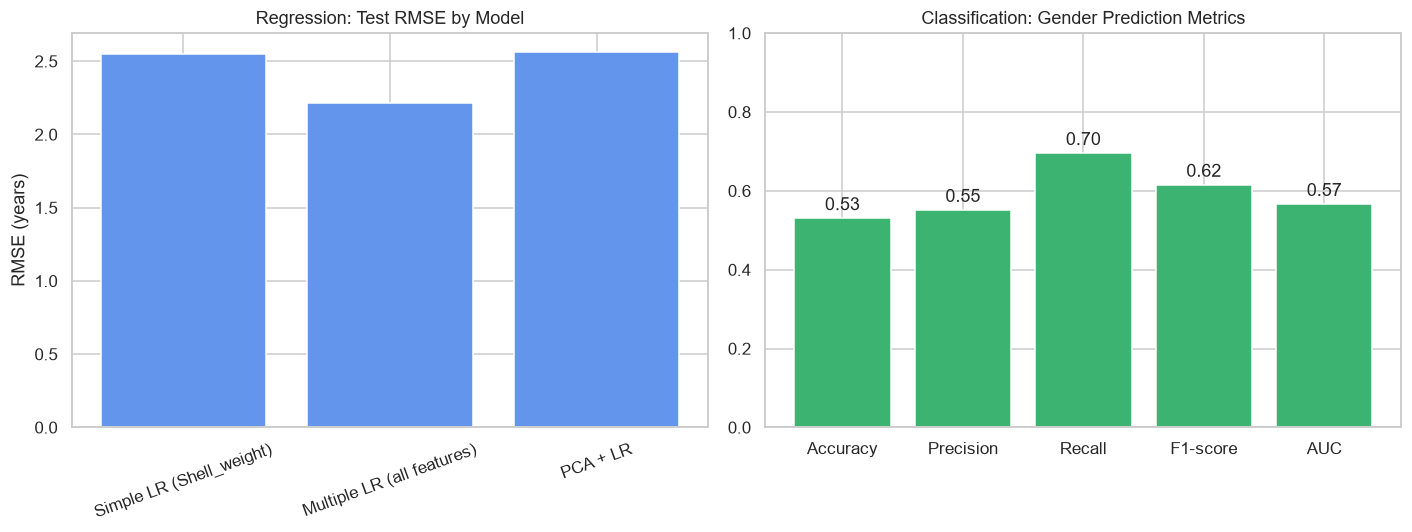

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(reg_compare["Model"], reg_compare["Test RMSE"], color="cornflowerblue")
axes[0].set_title("Regression: Test RMSE by Model")
axes[0].set_ylabel("RMSE (years)")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(clf_metrics["Metric"], clf_metrics["Score"], color="mediumseagreen")
axes[1].set_title("Classification: Gender Prediction Metrics")
axes[1].set_ylim(0, 1)
for i, v in enumerate(clf_metrics["Score"]):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.savefig("../images/10_final_summary.png", bbox_inches="tight")
plt.show()


---
## Conclusion

1. **Regression**: Multiple Linear Regression clearly outperforms Simple Linear Regression, since it
   combines multiple dimensions of data to predict age. PCA reduces the number of features while keeping
   performance close to that of Multiple Linear Regression.
2. **Classification**: Logistic Regression can distinguish gender (Male/Female) to some degree, but not with
   high accuracy, because the physical characteristics of males and females overlap considerably
   (unlike Infants, which are more clearly separable).
3. **Regression vs Classification**: Both are Supervised Learning techniques, but differ in the type of
   target (continuous vs categorical), which determines the appropriate algorithm and evaluation metrics
   for each problem.
